# Humidity and mould-risk indicators

**BQ2:** How can seasonal weather changes, air-con performance and humidity levels be analysed to detect zones at risk of air-con degradation, mould growth, or both?

**This notebook covers the mould half** for the 20 study zones: **Floors 3-7, zones 1, 2, 4, 5 only.** Floors 1-2 and zone 3 are excluded everywhere (Floor 1 and zone 3 have no humidity sensors; Floor 2 has a different layout), including in every average and median below. It produces one table, `outputs/bq2-humidity/zone_mould_metrics.csv`, which the joint notebook [`bq2_risk_matrix.ipynb`](bq2_risk_matrix.ipynb) combines with Track B's AC results.

| Step | Question | Why it matters for the matrix |
|---|---|---|
| 1. Load | Which window can every zone be compared over? | Fair comparison |
| 2. Mould exposure | How often is a surface damp enough for mould? | **The mould axis of the matrix** |
| 3. Seasons and 2018 | How does exposure change by season and from 2018 to 2019? | The seasonal-weather part of BQ2 |
| 4. Rebound | How fast does moisture return after the AC switches off? | **Links mould risk to the AC** |
| 5. Peer check | Did any zone get wetter than the other study zones from 2018 to 2019? | **Cross-checks Track B's leads** |
| 6. Zone table | One row per zone | Handover to the matrix |

**Why not just use RH?** RH rises whenever air cools, even if no moisture is added, and the baseline found all zones above 60% RH most of the time, so RH can't rank zones. This notebook uses **humidity ratio** (grams of water per kg of air) for moisture and **surface RH** for mould risk.

**Important:** the sensors measure room air, not surfaces, and no mould inspections exist. Results are **risk indicators for inspection priority**, not mould findings.

## 1. Load the data

The setup cell is the standard loading cell from [`docs/setup.md`](../../docs/setup.md). It loads the shared helper `bq2_utils.ipynb`, so the formulas are identical to Track B's.

**Analysis window: 2018 and 2019 together.** The indoor sensors have data for **Jul to mid-Sep 2018** and **from 7 Mar 2019**; Floor 6 stops on 22 Oct 2019. So the zone indicators use **Jul-Sep 2018 + 7 Mar-21 Oct 2019 combined**, the dates every zone has data for, giving one figure per zone that covers both years. Nov-Dec 2019 is left out of the combined figure because Floor 6 has no data then; it still appears in the seasonal view (Step 3).

In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "AGENTS.md").is_file()
                 and (p / "mould-ac-degradation/bq2_utils.ipynb").is_file())
analysis_dir = repo_root / "mould-ac-degradation"
sys.path.insert(0, str(analysis_dir / "src"))
RUN_CHECKS = False
helper_notebook = analysis_dir / "bq2_utils.ipynb"
get_ipython().run_line_magic("run", f'-i "{helper_notebook}"')

sys.path.insert(0, str(repo_root / "baseline"))
from humidity_risk_baseline import load_bangkok_era5_weather
weather = load_bangkok_era5_weather(repo_root / "baseline/data/bangkok_era5_hourly_2018-2019.csv")
df = merge_weather(load_zone_hourly(repo_root / "data-cleaning/outputs/analytics/zone_hourly.csv"), weather)
df["zone_id"] = "F" + df["floor"].astype(str) + "-Z" + df["zone"].astype(str)
df["valid"] = df["temp_C"].notna() & df["rh_pct"].notna()

CLEAN_DIR = repo_root / "data-cleaning/outputs/clean"
OUT_DIR = analysis_dir / "outputs/bq2-humidity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Settings
MOULD_RH = 80                     # surface RH (%) at which mould growth becomes possible
SURFACE_DROP_C = 2                # main scenario: surface 2 °C cooler than the room air
SENSITIVITY_DROP_C = 4            # sensitivity scenario: 4 °C cooler
WINDOWS = [("2018-07-01", "2018-09-30 23:00"),     # all 2018 sensor data (it stops mid-Sep)
           ("2019-03-07", "2019-10-21 23:00")]     # 2019 until Floor 6's data ends

def in_window(dates):
    """True for timestamps inside either window (both years together)."""
    dates = pd.Series(dates)
    return np.any([dates.between(a, b) for a, b in WINDOWS], axis=0)

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#a3a29c", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})

suspect = set(df.loc[df["suspect_sensor"], "zone_id"])           # F5-Z1: unusually cold sensor
common = df[in_window(df["Date"])]
v = common[common["valid"]].copy()
coverage = pd.DataFrame({"rh_coverage_pct": df.groupby("zone_id")["valid"].mean() * 100,
                         "common_window_coverage_pct": common.groupby("zone_id")["valid"].mean() * 100}).round(1)
assert set(df["floor"]) <= {3, 4, 5, 6, 7} and set(df["zone"]) <= {1, 2, 4, 5}
print(f"Scope: floors {sorted(df['floor'].unique().tolist())}, zones {sorted(df['zone'].unique().tolist())}")
print(f"{df['zone_id'].nunique()} zones; combined-window coverage {coverage['common_window_coverage_pct'].min():.0f}-"
      f"{coverage['common_window_coverage_pct'].max():.0f}% (lowest: "
      f"{', '.join(coverage['common_window_coverage_pct'].nsmallest(4).index)})")

**What this shows:** all 20 zones load. Most have about 86-93% of hours in the combined window; F5-Z2, F5-Z1, F4-Z4 and F3-Z5 have less (65-73%), so their results are flagged as lower confidence in the zone table.

## 2. Mould exposure: surface RH and time of wetness

**What we're checking:** mould grows on **surfaces**, and a surface cooler than the room air is damper than the air (same moisture, lower temperature, higher RH). Surface temperatures weren't measured, so we **assume** a surface **2 °C cooler** than the room (an exterior wall, a ceiling near a diffuser), and test **4 °C** as a sensitivity.

| Indicator | Definition |
|---|---|
| `time_of_wetness_h` | Hours per week with surface RH ≥ 80%. **The mould axis of the matrix.** |
| `peak_30d_surface_rh` | Highest 30-day running mean of surface RH (needs 360+ valid hours). The older ASHRAE Standard 160 criterion treats a 30-day mean ≥ 80% as a mould-growth risk. |

**Priority rule:** "Inspect first" if `peak_30d_surface_rh` ≥ 80% (sustained damp conditions), otherwise "Monitor". F5-Z1 is "Check sensor first" because its sensor reads unusually cold.

In [ ]:
v["surface_rh"] = surface_rh_pct(v["indoor_dew_C"], v["temp_C"] - SURFACE_DROP_C)
v["surface_rh_4C"] = surface_rh_pct(v["indoor_dew_C"], v["temp_C"] - SENSITIVITY_DROP_C)

def hours_per_week_wet(s):
    return (s >= MOULD_RH).mean() * 168

def peak_30_day_mean(g):
    return g.set_index("Date")["surface_rh"].sort_index().rolling("30D", min_periods=360).mean().max()

mould = pd.DataFrame({
    "time_of_wetness_h": v.groupby("zone_id")["surface_rh"].apply(hours_per_week_wet),
    "time_of_wetness_4C_h": v.groupby("zone_id")["surface_rh_4C"].apply(hours_per_week_wet),
    "peak_30d_surface_rh": v.groupby("zone_id").apply(peak_30_day_mean),
}).round(1)
mould["meets_30d_criterion"] = mould["peak_30d_surface_rh"] >= MOULD_RH
mould["mould_priority"] = np.where(mould.index.isin(suspect), "Check sensor first",
                                   np.where(mould["meets_30d_criterion"], "Inspect first", "Monitor"))

order = mould.sort_values("time_of_wetness_h").index
colors = {"Inspect first": ORANGE, "Monitor": BLUE, "Check sensor first": GREY}
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(order, mould.loc[order, "time_of_wetness_h"], color=[colors[p] for p in mould.loc[order, "mould_priority"]], height=0.7)
for z in order:
    ax.text(mould.loc[z, "time_of_wetness_h"] + 1, z, f"{mould.loc[z, 'time_of_wetness_h']:.0f}", va="center", fontsize=8, color=INK)
ax.set_xlim(0, 168)
ax.set_xlabel(f"Hours per week with surface RH ≥ {MOULD_RH}% (surface {SURFACE_DROP_C} °C cooler than room air)")
ax.set_title("Mould exposure by zone (Jul-Sep 2018 + Mar-Oct 2019)", loc="center", pad=20)
ax.legend(handles=[Patch(color=c, label=p) for p, c in colors.items()], loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "time_of_wetness.png", bbox_inches="tight")
plt.show()
monthly = v.assign(month=v["Date"].dt.to_period("M")).groupby(["zone_id", "month"])["surface_rh"].apply(hours_per_week_wet)
balanced = monthly.groupby("zone_id").mean()
print(f"Fairness check: pooled hours vs every month weighted equally, rank correlation "
      f"{mould['time_of_wetness_h'].corr(balanced, method='spearman'):.3f}")
print(f"At {SENSITIVITY_DROP_C} °C cooler, damp hours per week range "
      f"{mould['time_of_wetness_4C_h'].min():.0f}-{mould['time_of_wetness_4C_h'].max():.0f} across all zones.")

**What this shows:**

- **One figure per zone covering both years.** Each bar is the share of all measured hours in Jul-Sep 2018 and Mar-Oct 2019 with damp surfaces. 2018 adds few damp hours (Step 3 shows why), which lowers every zone's figure, but the order of the zones stays the same.
- **The pooling is fair:** zones have slightly different amounts of 2018 vs 2019 data, so we also weighted every month equally. The ranking is essentially unchanged (rank correlation above 0.99).
- **The zones separate clearly.** The dampest zones (**F3-Z5, F5-Z4, F5-Z5, F4-Z5, F7-Z2, F3-Z4**) have damp surfaces for about **55-107 hours a week**; the driest (**F3-Z1, F4-Z1, F6-Z4**) under 13.
- **Nine ranked zones are "Inspect first"**: their surfaces stayed damp on average for a whole month.
- **F5-Z2 is borderline** (30-day peak 79.5%, just under 80%) and is missing August-September, its likely wettest months, so treat it as a probable "Inspect first".
- **Sensitivity:** with surfaces 4 °C cooler, every zone is damp for at least 62 hours a week. Humidity is a problem **across all 20 study zones** in the wet months; the ranking shows where it is **worst**.

## 3. Reason for Damp Zone

**What we are checking:** a surface gets damp either because the air holds **more moisture** or because the room is **colder** (same moisture, lower temperature). Each needs a different fix. For every zone we compare its average moisture and temperature with the **typical zone at the same hour** (the 20-zone median). A zone counts as **wetter** if it holds more than 0.2 g/kg extra moisture, and **colder** if it is more than 0.2 °C below typical. Smaller differences count as typical.

In [ ]:
# Is each zone damp because of wetter air or a colder room? Compare it with the typical zone at the same hour.
v["typical_w"] = v.groupby("Date")["indoor_w_gkg"].transform("median")   # 20-zone median moisture
v["typical_T"] = v.groupby("Date")["temp_C"].transform("median")         # 20-zone median temperature
drivers = pd.DataFrame({
    "damp_hours": mould["time_of_wetness_h"],
    "moisture_vs_typical_gkg": (v["indoor_w_gkg"] - v["typical_w"]).groupby(v["zone_id"]).mean(),
    "temp_vs_typical_C": (v["temp_C"] - v["typical_T"]).groupby(v["zone_id"]).mean(),
}).round(2)
wetter = drivers["moisture_vs_typical_gkg"] > 0.2      # differences of 0.2 or less count as typical
colder = drivers["temp_vs_typical_C"] < -0.2
drivers["damp_driver"] = np.select([wetter & colder, wetter, colder], ["Both", "Wetter air", "Colder room"],
                                   default="Neither (typical)")

# Chart: building grid (floors x zones), each box coloured by the cause of dampness
DRIVER_COLOR = {"Colder room": BLUE, "Wetter air": "#1baf7a", "Both": ORANGE, "Neither (typical)": "#e4e3df"}
FLOORS, ZONES = [7, 6, 5, 4, 3], [1, 2, 4, 5]                 # top floor at the top

def reason(r):
    parts = []
    if r["temp_vs_typical_C"] < -0.2:
        parts.append(f"{-r['temp_vs_typical_C']:.1f} °C colder")
    if r["moisture_vs_typical_gkg"] > 0.2:
        parts.append(f"+{r['moisture_vs_typical_gkg']:.1f} g/kg")
    return "\n".join(parts) or "typical"

fig, ax = plt.subplots(figsize=(8, 6.5))
for i, f in enumerate(FLOORS):
    for j, zn in enumerate(ZONES):
        z = f"F{f}-Z{zn}"
        r = drivers.loc[z]
        color = DRIVER_COLOR[r["damp_driver"]]
        ax.add_patch(plt.Rectangle((j, -i), 0.94, 0.9, color=color))
        text_color = INK if r["damp_driver"] == "Neither (typical)" else "white"
        ax.text(j + 0.47, -i + 0.62, z, ha="center", va="center", fontsize=10, fontweight="bold", color=text_color)
        note = reason(r) + ("\n(check sensor)" if z in suspect else "")
        ax.text(j + 0.47, -i + 0.3, note, ha="center", va="center", fontsize=8.5, color=text_color)
ax.set_xlim(-0.05, len(ZONES))
ax.set_ylim(-len(FLOORS) + 0.95, 0.95)
ax.set_xticks([j + 0.47 for j in range(len(ZONES))], [f"Zone {zn}" for zn in ZONES])
ax.set_yticks([-i + 0.45 for i in range(len(FLOORS))], [f"Floor {f}" for f in FLOORS])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Why is each zone damp?", loc="center", pad=30)
ax.legend(handles=[Patch(color=c, label=d) for d, c in DRIVER_COLOR.items()], loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "damp_drivers.png", bbox_inches="tight")
plt.show()
drivers.sort_values(["damp_driver", "damp_hours"], ascending=[True, False])

   **What this shows:**

   - **Colder room (7 zones, mostly Floors 3-4):** typical moisture but 0.3-1.4 °C colder than other zones, led by F3-Z5 (106 h, 1.4 °C colder). Check AC setpoints / overcooling, or whether the sensors read cold. Matches Track B: F3-Z4's AC runs more continuously.
   - **Wetter air (4 zones, mostly Floor 7):** up to 1.3 g/kg more moisture than other zones. Check ventilation, moisture sources and AC dehumidification. Matches Track B's F7-Z2 finding.
   - **Both (F5-Z4, F7-Z1)** and **typical (7 zones, mostly Floor 6).**

## 4. Mould exposure based on season

**What we're checking:** how mould exposure changes by season, and whether 2018 looks like 2019. The sensors have data for four periods; within each, every zone is measured over the same dates:

| Period | Dates |
|---|---|
| Rainy 2018 | Jul-Sep 2018 |
| Hot 2019 | Mar-May 2019 |
| Rainy 2019 | Jun-21 Oct 2019 |
| Cool 2019 | Nov-Dec 2019 (no Floor 6 data) |

In [ ]:
PERIODS = {"Rainy 2018": ("2018-07-01", "2018-09-30 23:00"), "Hot 2019": ("2019-03-01", "2019-05-31 23:00"),
           "Rainy 2019": ("2019-06-01", "2019-10-21 23:00"), "Cool 2019": ("2019-11-01", "2019-12-31 23:00")}
df["surface_rh"] = surface_rh_pct(df["indoor_dew_C"], df["temp_C"] - SURFACE_DROP_C)

period_rows, summary_rows = [], []
for name, (start, end) in PERIODS.items():
    p = df[df["Date"].between(start, end) & df["valid"]]
    period_rows.append(p.groupby("zone_id")["surface_rh"].apply(hours_per_week_wet).rename(name))
    summary_rows.append({"period": name, "outdoor_moisture_gkg": p["outdoor_w_gkg"].mean(),
                          "indoor_moisture_gkg": p["indoor_w_gkg"].mean(),
                          "indoor_temp_AC_on_C": p.loc[p["ac_kW"] > 0.5, "temp_C"].mean(),
                          "damp_hours_per_week": hours_per_week_wet(p["surface_rh"])})
period_tow = pd.concat(period_rows, axis=1).round(1)
period_tow.rename_axis("zone_id").reset_index().melt(id_vars="zone_id", var_name="period", value_name="time_of_wetness_h") \
    .to_csv(OUT_DIR / "zone_period_metrics.csv", index=False)

grid = period_tow.loc[list(mould.drop(index=list(suspect)).sort_values("time_of_wetness_h", ascending=False).index) + sorted(suspect)]
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.imshow(grid.to_numpy(dtype=float), cmap=LinearSegmentedColormap.from_list("blue", ["#eef4fc", "#0d3c78"]),
          vmin=0, vmax=140, aspect="auto")
for i, z in enumerate(grid.index):
    if z in suspect:  
        ax.add_patch(plt.Rectangle((-0.5, i - 0.5), len(grid.columns), 1, color=GREY, zorder=2))
    for j, period in enumerate(grid.columns):
        value = grid.loc[z, period]
        ax.text(j, i, "no data" if pd.isna(value) else f"{value:.0f}", ha="center", va="center", fontsize=8,
                color=INK if z in suspect or not value > 70 else "white", zorder=3)
ax.legend(handles=[Patch(color=GREY, label="Check sensor first")],
          loc="upper center", bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=8)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.xaxis.tick_top()
ax.grid(False)
ax.set_title(("Hours per week with surface RH ≥ 80%"), loc="center", pad=35)
fig.tight_layout()
fig.savefig(OUT_DIR / "time_of_wetness_by_period.png", bbox_inches="tight")
plt.show()
pd.DataFrame(summary_rows).set_index("period").round(1)

**What this shows:**

- **Season matters** (averages over the 20 study zones): surfaces are damp about **50 hours a week** in the hot and rainy seasons of 2019, but only about **8** in the cool season. Mould exposure is concentrated from March to October.
- **The dampest zones are consistent:** F3-Z5 and F5-Z4 are among the three dampest ranked zones in every 2019 period.
- **2018 was much drier at surfaces: about 5 damp hours a week, against about 50 in the same rainy months of 2019.** The weather was almost the same, and indoor air actually held *less* moisture in 2019. But rooms read **about 2.6 °C colder with the AC on** (21.4 vs 24.0 °C), and colder rooms make surfaces damper.
- **So 2019's higher mould exposure comes from colder rooms, not wetter air.** Either the zones were run colder (Track B also found cooler 2019 temperatures and higher AC power in F3-Z4 and F5-Z4), or the sensors read colder after the firmware update between the two years. Both years are included in the main indicator (Step 2); this view shows how that combined figure splits by period.

## 5. Moisture rebound after AC shutdown

**What we're checking:** this is the link between the AC and mould. While the AC runs it removes moisture; when it switches off (lunch, evenings), moisture returns. A **fast rebound** means moisture gets into the zone easily, so the zone depends heavily on the AC staying on.

**How (minute data):** find every AC shutdown with the shared `detect_ac_events` helper; keep it only if the next 60 minutes are complete (61 consecutive minutes, valid temperature and RH, AC still off). **Rebound rate** = rise in humidity ratio over that hour (g/kg per hour); each zone's value is the median over its shutdowns. Takes about a minute.

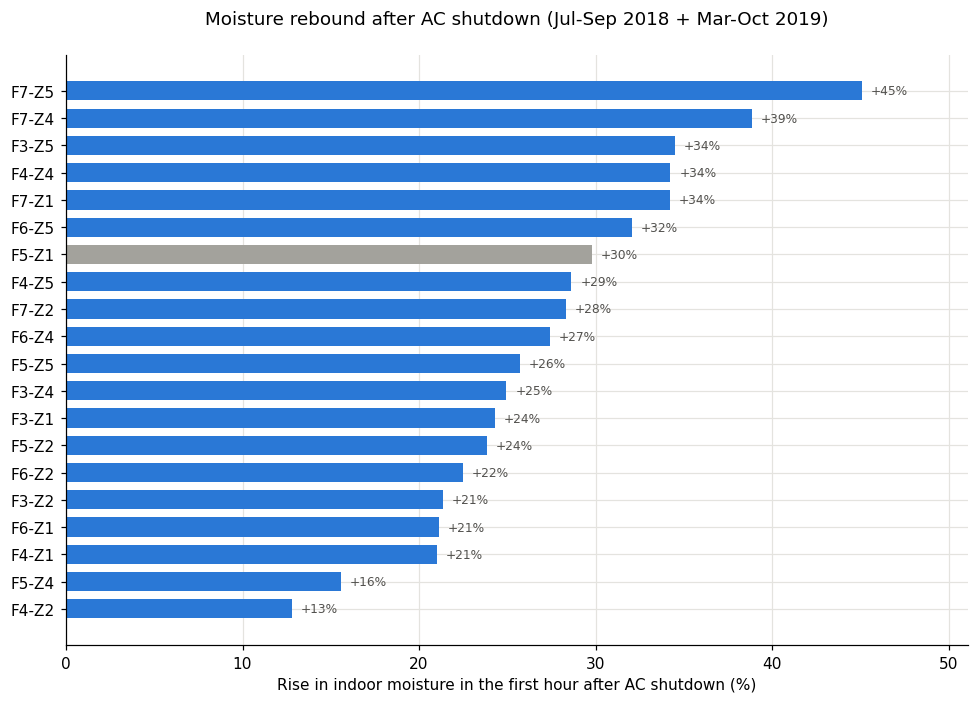

5,290 usable shutdowns. Typical rise in the first hour: +26% (RH changes -2.5 points, because the room warms as moisture rises).


In [35]:
# Read each floor's minute files ONCE (not once per zone) - same data as zone_minute_series(), ~4x faster
floor_cache = {}
def zone_minutes(f, z):
    if f not in floor_cache:
        floor_cache[f] = pd.concat([pd.read_csv(CLEAN_DIR / f"{y}Floor{f}.csv", parse_dates=["Date"], index_col="Date")
                                    for y in (2018, 2019)])
    d = floor_cache[f]
    ac_cols = [c for c in d.columns if c.startswith(f"z{z}_AC")]
    m = pd.DataFrame(index=d.index)
    m["ac_kW"] = d[ac_cols].sum(axis=1, min_count=len(ac_cols))
    m["temp_C"] = d[f"z{z}_S1(degC)"]
    m["rh_pct"] = d[f"z{z}_S1(RH%)"]
    m["indoor_w_gkg"] = humidity_ratio_gkg(m["temp_C"], m["rh_pct"])
    return m

zones = df[["floor", "zone", "zone_id"]].drop_duplicates().sort_values(["floor", "zone"])
rows = []
for f, z, zid in zones.itertuples(index=False):
    m = zone_minutes(f, z)
    m = m[in_window(m.index)]
    events = detect_ac_events(m["ac_kW"])
    threshold = events["threshold_kW"].iloc[0] if len(events) else np.nan
    for t in events.loc[events["event"] == "stop", "time"]:
        w = m.loc[t:t + pd.Timedelta(minutes=60)]
        if len(w) == 61 and w[["temp_C", "rh_pct"]].notna().all().all() and (w["ac_kW"] <= threshold).all():
            start, end = w["indoor_w_gkg"].iloc[0], w["indoor_w_gkg"].iloc[-1]
            rows.append({"zone_id": zid, "time": t,
                         "moisture_rise_gkg": end - start,
                         "moisture_rise_pct": (end - start) / start * 100,
                         "rh_change_pct": w["rh_pct"].iloc[-1] - w["rh_pct"].iloc[0]})
del floor_cache
rebound_events = pd.DataFrame(rows)
rebound_events.to_csv(OUT_DIR / "rebound_events.csv", index=False)
rebound = rebound_events.groupby("zone_id").agg(rebound_rate=("moisture_rise_gkg", "median"),
                                                rebound_pct=("moisture_rise_pct", "median"),
                                                rebound_events=("moisture_rise_gkg", "size"),
                                                median_rh_change_pct=("rh_change_pct", "median")).round(2)

order = rebound.sort_values("rebound_pct").index
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(order, rebound.loc[order, "rebound_pct"], color=[GREY if z in suspect else BLUE for z in order], height=0.7)
for z in order:
    ax.text(rebound.loc[z, "rebound_pct"] + 0.5, z, f"+{rebound.loc[z, 'rebound_pct']:.0f}%", va="center", fontsize=8, color=INK)
ax.set_xlim(0, rebound["rebound_pct"].max() + 6)
ax.set_xlabel("Rise in indoor moisture in the first hour after AC shutdown (%)")
ax.set_title("Moisture rebound after AC shutdown (Jul-Sep 2018 + Mar-Oct 2019)", loc="center", pad=20)
fig.tight_layout()
fig.savefig(OUT_DIR / "rebound_rate.png", bbox_inches="tight")
plt.show()
print(f"{len(rebound_events):,} usable shutdowns. Typical rise in the first hour: "
      f"+{rebound_events['moisture_rise_pct'].median():.0f}% (RH changes {rebound_events['rh_change_pct'].median():+.1f} points, "
      f"because the room warms as moisture rises).")

**What this shows:**

- **Moisture returns fast everywhere:** **1.4-4.5 g/kg in the first hour** after shutdown. The AC is the main dehumidifier in these zones, so any AC weakness or longer off-period shows up directly as moisture.
- **RH hides this:** over the same hour RH usually *falls* slightly because the room warms up, which is another reason to use humidity ratio.
- **Floor 7 rebounds fastest** (F7-Z5, F7-Z4, F7-Z1 and F7-Z2 are in the top six): moisture reaches it most easily.
- F6-Z5 has only 15 usable shutdowns, so its rate is flagged as lower confidence.

## 6. Relative moisture change by zone 

**What we're checking:** at each hour we subtract the **median moisture of the 20 study zones** from each zone's moisture, so weather and season cancel out. We then compare the average for **Jul-Aug 2018** and **Jul-Aug 2019** (working days), the same months Track B compares. A zone whose offset jumps became wetter *relative to the other study zones*: a local change (AC, ventilation, a moisture source) or a sensor that drifted.

In [ ]:
df["peer_offset_gkg"] = df["indoor_w_gkg"] - df.groupby("Date")["indoor_w_gkg"].transform("median")
jul_aug = df[df["Date"].dt.month.isin([7, 8]) & (df["day_type"] == "working day")]
peer = jul_aug.groupby(["zone_id", "year"])["peer_offset_gkg"].mean().unstack()
peer.columns = ["offset_2018_gkg", "offset_2019_gkg"]
peer["peer_offset_change_gkg"] = peer["offset_2019_gkg"] - peer["offset_2018_gkg"]
peer = peer.round(2).sort_values("peer_offset_change_gkg")
peer.tail(3)   # shows the 3 zones that got wettest relative to the others

**What this shows:**

- **F7-Z2 stands out: +1.9 g/kg** relative to the other study zones from 2018 to 2019. Track B independently found F7-Z2 about +1.15 g/kg wetter during sustained AC operation. **Two different methods point at the same zone.**
- **F7-Z4 also rose (+1.05 g/kg)** and the rest of Floor 7 slightly, so part of the change may be floor-wide (shared ventilation, controls, or sensors reinstalled together).
- Because the sensors were removed for a firmware update between the two years, verify the F7-Z2 sensor before attributing the change to the AC.

## 7. Zone table (handover to the risk matrix)

One row per zone, saved to `outputs/bq2-humidity/zone_mould_metrics.csv`. The [risk-matrix notebook](bq2_risk_matrix.ipynb) reads it.

| Column | Unit | Meaning |
|---|---|---|
| `mould_priority` | | Inspect first / Monitor / Check sensor first (Step 2) |
| `time_of_wetness_h` | hours/week | Surface RH ≥ 80%, surface 2 °C cooler, Jul-Sep 2018 + 7 Mar-21 Oct 2019 combined. **Mould axis** |
| `time_of_wetness_4C_h` | hours/week | Same, 4 °C cooler (sensitivity) |
| `peak_30d_surface_rh` | % | Highest 30-day mean surface RH; `meets_30d_criterion` = ≥ 80% |
| `tow_rainy_2018_h` ... `tow_cool_2019_h` | hours/week | Time of wetness in each period (Step 3) |
| `rebound_rate` | g/kg per hour | Median moisture rise in the hour after AC shutdown; `rebound_events` = shutdowns used |
| `humidity_sensitivity` | g/kg per g/kg | Rise in daily indoor moisture per 1 g/kg of outdoor moisture (working days, measured within each year so the 2018-2019 shift doesn't distort it) |
| `peer_offset_change_gkg` | g/kg | Change relative to the 20-zone median, Jul-Aug 2019 minus 2018 |
| `rh_coverage_pct`, `common_window_coverage_pct` | % | Valid temperature + RH hours, whole 18 months / combined window |
| `suspect_sensor`, `note` | | Sensor flag; lower-confidence reasons |

In [ ]:
# humidity_sensitivity: slope of daily indoor vs outdoor moisture (working days, combined window).
# Each year's average is removed first, so the 2018 -> 2019 shift doesn't distort the slope.
daily = (v[v["day_type"] == "working day"].assign(day=lambda d: d["Date"].dt.normalize())
         .groupby(["zone_id", "year", "day"])[["indoor_w_gkg", "outdoor_w_gkg"]].mean().dropna())
daily = daily - daily.groupby(["zone_id", "year"]).transform("mean")
sensitivity = daily.groupby("zone_id").apply(lambda g: np.polyfit(g["outdoor_w_gkg"], g["indoor_w_gkg"], 1)[0])

table = (mould
         .join(period_tow.rename(columns=lambda p: "tow_" + p.lower().replace(" ", "_") + "_h"))
         .join(rebound[["rebound_rate", "rebound_events"]])
         .join(sensitivity.rename("humidity_sensitivity").round(2))
         .join(peer["peer_offset_change_gkg"])
         .join(coverage))
table["suspect_sensor"] = table.index.isin(suspect)
table["note"] = ""
table.loc[table["suspect_sensor"], "note"] += "Suspect sensor (unusually cold readings); "
table.loc[table["common_window_coverage_pct"] < 75, "note"] += "Low humidity coverage in window; "
table.loc[table["rebound_events"] < 30, "note"] += "Few usable shutdowns for rebound; "
table["note"] = table["note"].str.rstrip("; ")

table["order"] = table["mould_priority"].map({"Inspect first": 1, "Monitor": 2, "Check sensor first": 3})
table = table.sort_values(["order", "time_of_wetness_h"], ascending=[True, False]).drop(columns="order")
table = table.rename_axis("zone_id").reset_index()
table.insert(1, "floor", table["zone_id"].str[1].astype(int))
table.insert(2, "zone", table["zone_id"].str[-1].astype(int))
table.to_csv(OUT_DIR / "zone_mould_metrics.csv", index=False)
table[["zone_id", "mould_priority", "time_of_wetness_h", "rebound_rate", "peer_offset_change_gkg", "note"]]

## 8. Findings and limitations

**Mould half of BQ2:**

1. **Surface RH ranks the zones.** Nine zones are "Inspect first" (30-day mean surface RH ≥ 80% with surfaces only 2 °C cooler than the room). F3-Z5, F5-Z4, F5-Z5, F4-Z5, F7-Z2 and F3-Z4 are damp for the most hours.
2. **Two causes need two fixes:** colder rooms on Floors 3-4 (check setpoints / sensors) and wetter air on Floor 7 (check ventilation / AC dehumidification).
3. **Seasonal weather drives exposure:** about 50 damp hours a week from March to October, about 8 in Nov-Dec.
4. **2019 was far damper at surfaces than 2018** in the same weather, because rooms read colder, not because the air was wetter. Check whether that is real overcooling or a sensor change.
5. **The AC is the main dehumidifier:** moisture returns within an hour of shutdown, fastest on Floor 7.
6. **F7-Z2 is the strongest joint lead:** largest moisture rise relative to the other study zones, matching Track B. Verify its sensor first.

**Suggested KPI:** hours per week with surface RH ≥ 80% (`time_of_wetness_h`) in the "Inspect first" zones, tracked monthly.

**Limitations:** room-air sensors, not surfaces, so the 2 °C / 4 °C surface scenarios are assumptions and the **ranking** matters more than the absolute hours. The 80% / 30-day criterion is from the older ASHRAE 160 approach. Sensor calibration across the 2018-19 firmware update is unverified. No occupancy, ventilation, setpoint or mould-inspection records exist, so these indicators show **where to inspect first**, not confirmed mould.